### 30000 feet view

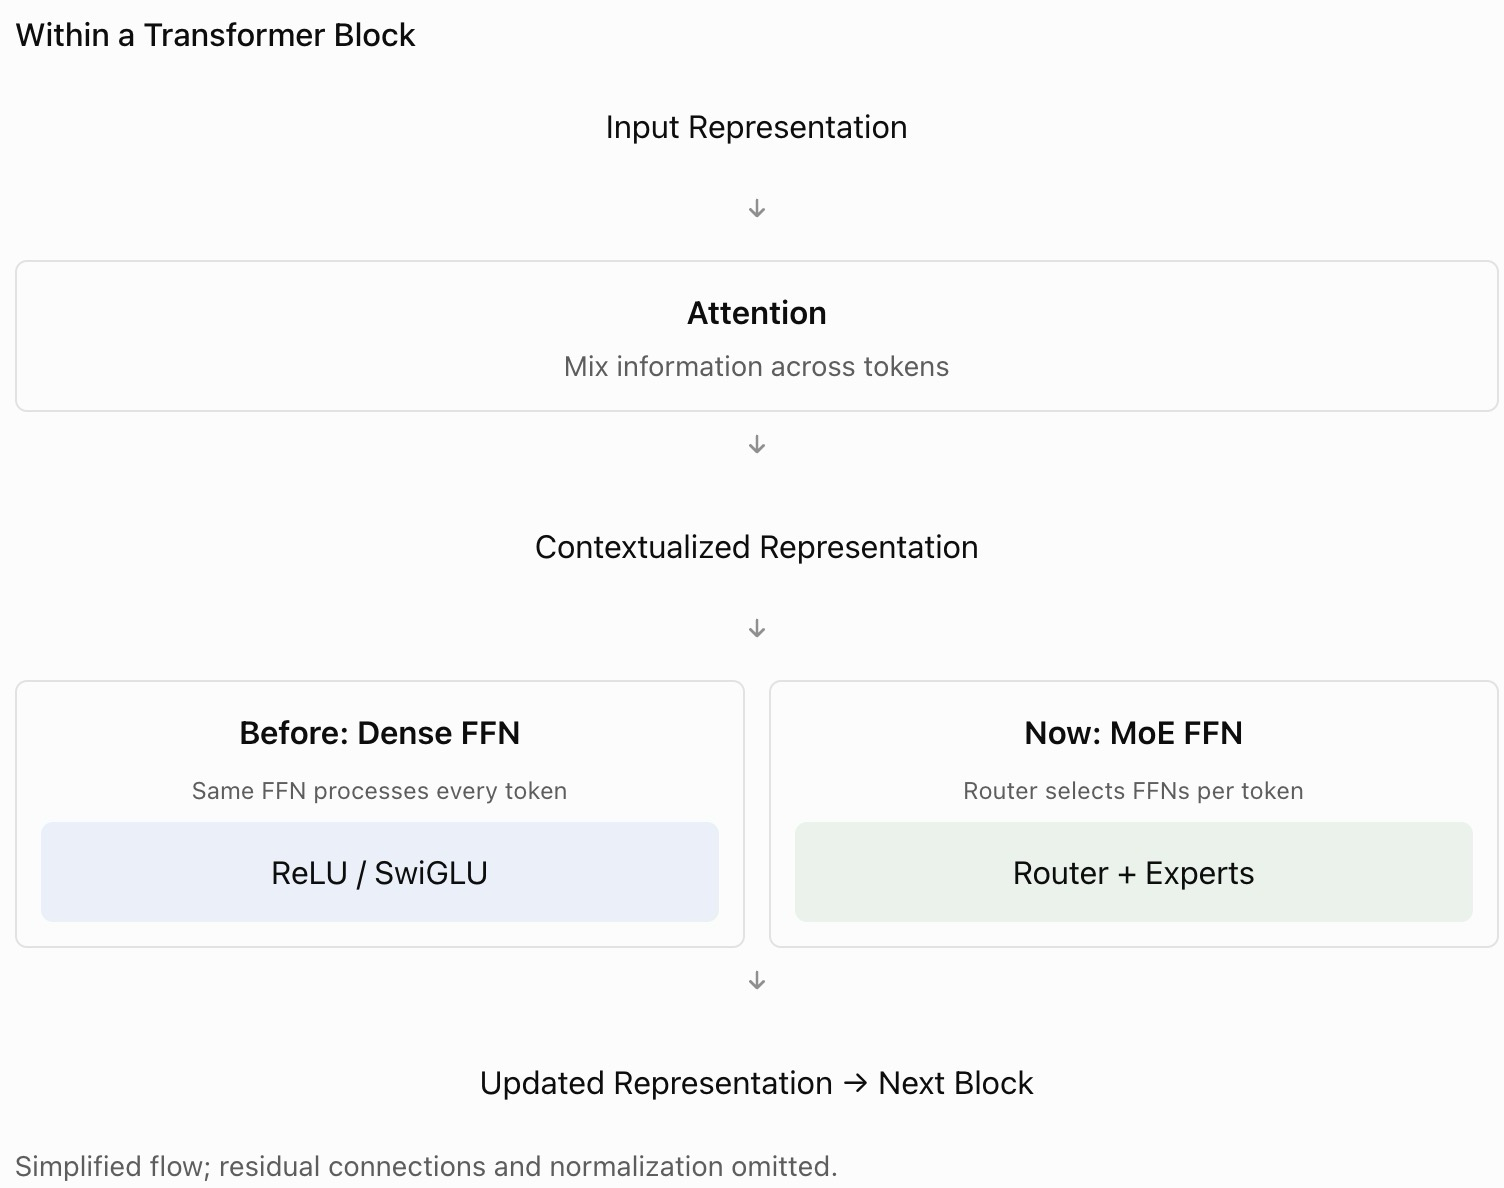

In [1]:
import numpy as np

x = np.array([
    [3., 1.],
    [1., 3.],
    [-2., -1.]
])

router_W = np.array([
    [1., 0.],
    [0., 1.],
    [-1., -1.]
])

experts = np.array([
    [[2., 0.], [0., 1.]],
    [[1., 0.], [0., 2.]],
    [[-1., 0.], [0., -1.]]
])

scores = x @ router_W.T
chosen = scores.argmax(axis=1)

y = np.stack([
    x[i] @ experts[j]
    for i, j in enumerate(chosen)
])

print("Chosen experts:", chosen)
print("Outputs:\n", y)

Chosen experts: [0 1 2]
Outputs:
 [[6. 1.]
 [1. 6.]
 [2. 1.]]


## Issue: argmax cannot do backprop

In [3]:
import torch

for mode in ["hard", "gated"]:
    # router weights, we want to learn this
    logits = torch.tensor([2.0, 1.0], requires_grad=True)

    # the corresponding experts
    experts = torch.tensor([2.0, -1.0], requires_grad=True)

    probs = torch.softmax(logits, dim=0)
    idx = probs.argmax()

    y = experts[idx]

    # This is the key!!
    # Create a differentiable path from the loss to the router weights.
    if mode == "gated":
        y = probs[idx] * y

    loss = (y - 1.0) ** 2
    loss.backward()

    print(mode)
    print("  router grad:", logits.grad)
    print("  expert grad:", experts.grad)

hard
  router grad: None
  expert grad: tensor([2., 0.])
gated
  router grad: tensor([ 0.3634, -0.3634])
  expert grad: tensor([0.6757, 0.0000])


## A more realistic example

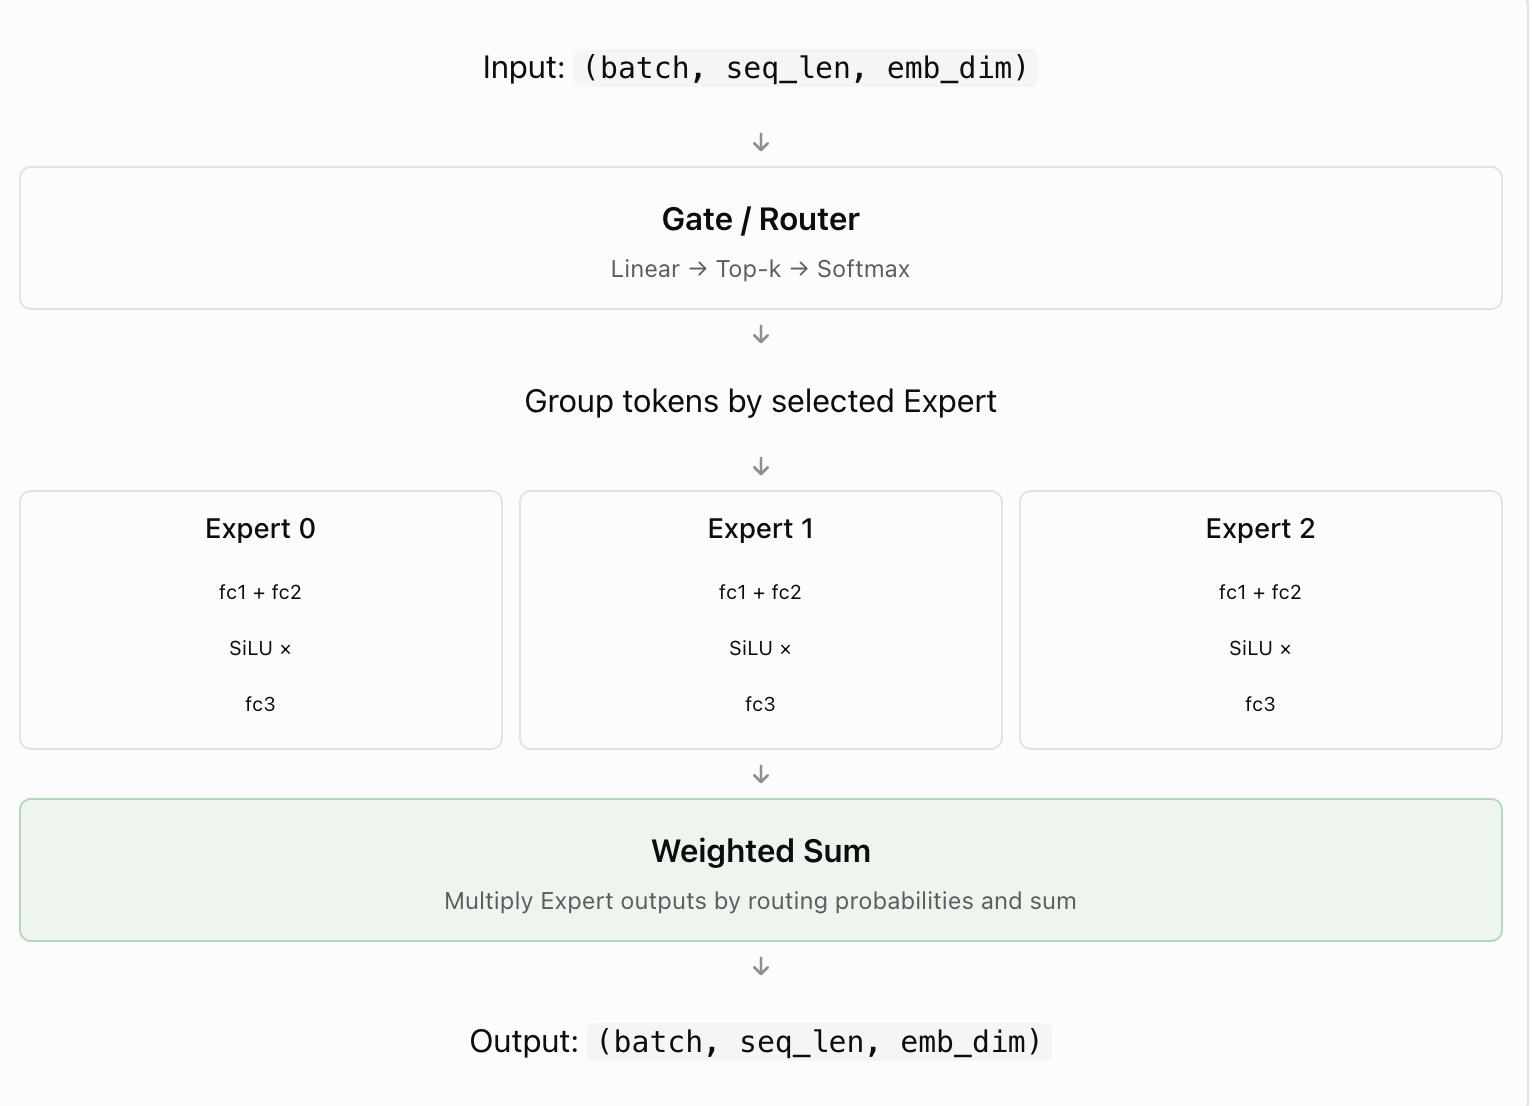

## Essense of the block:

Read forward()!!


<img src="./moe_expert.svg" width="500">

Here, 1 expert is just a SwiGLU.

In [2]:
import torch.nn as nn

# Full code example
class MoEFeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.num_experts_per_tok = cfg["num_experts_per_tok"]
        self.num_experts = cfg["num_experts"]
        self.emb_dim = cfg["emb_dim"]

        self.gate = nn.Linear(cfg["emb_dim"], cfg["num_experts"], bias=False)

        # For SwiGLU
        self.fc1 = nn.ModuleList(
            [
                nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], bias=False)
                for _ in range(self.num_experts)
            ]
        )
        self.fc2 = nn.ModuleList(
            [
                nn.Linear(cfg["emb_dim"], cfg["hidden_dim"], bias=False)
                for _ in range(self.num_experts)
            ]
        )
        self.fc3 = nn.ModuleList(
            [
                nn.Linear(cfg["hidden_dim"], cfg["emb_dim"], bias=False)
                for _ in range(self.num_experts)
            ]
        )

    def forward(self, x):
        # x: (batch, seq_len, emb_dim)
        scores = self.gate(x)  # (b, seq_len, num_experts)
        topk_scores, topk_indices = torch.topk(scores, self.num_experts_per_tok, dim=-1)
        topk_probs = torch.softmax(topk_scores, dim=-1)

        # Group tokens by Expert, so each Expert can process all its assigned tokens in a single batched forward pass.
        batch, seq_len, _ = x.shape
        x_flat = x.reshape(batch * seq_len, -1)

        # out_flat is for accumulating weighted outputs
        out_flat = torch.zeros(batch * seq_len, self.emb_dim, device=x.device, dtype=x.dtype)

        topk_indices_flat = topk_indices.reshape(-1, self.num_experts_per_tok)
        topk_probs_flat = topk_probs.reshape(-1, self.num_experts_per_tok)

        unique_experts = torch.unique(topk_indices_flat)

        for expert_id_tensor in unique_experts:
            expert_id = int(expert_id_tensor.item())

            mask = topk_indices_flat == expert_id
            if not mask.any():
                continue

            token_mask = mask.any(dim=-1)
            selected_idx = token_mask.nonzero(as_tuple=False).squeeze(-1)
            if selected_idx.numel() == 0:
                continue

            expert_input = x_flat.index_select(0, selected_idx)
            hidden = torch.nn.functional.silu(self.fc1[expert_id](expert_input)) * self.fc2[
                expert_id
            ](expert_input)
            expert_out = self.fc3[expert_id](hidden)

            mask_selected = mask[selected_idx]
            slot_indices = mask_selected.int().argmax(dim=-1, keepdim=True)
            selected_probs = torch.gather(
                topk_probs_flat.index_select(0, selected_idx), dim=-1, index=slot_indices
            ).squeeze(-1)

            out_flat.index_add_(0, selected_idx, expert_out * selected_probs.unsqueeze(-1))

        return out_flat.reshape(batch, seq_len, self.emb_dim)
